## Generating molecule training images

We saw in the previous Notebook that training images that are just atoms don't work, as the model doesn't know what to do with them in the context of an image of a whole molecule.  Groan.

We are back at the drawing board now.  Lets try generating the required number of images for each atom type again...

We can use the `element_counts` dataframe we saved to csv in Notebook `01` to help work out the minimum number of images we need to get, say, 5,000 images per atom type.  We can start with the least common atom as those molecules will likely also contain the most common atoms, reducing the total number of images we need to generate.

In [3]:
import pandas as pd

df_element_counts = pd.read_csv("../data/element_counts.csv", index_col="image_id")
df_element_counts

,B,Br,C,Cl,F,H,I,N,O,P,S,Si
image_id,,,,,,,,,,,,
000011a64c74,0,0,13,0,0,20,0,0,1,0,1,0
000019cc0cd2,0,0,21,0,0,30,0,0,4,0,0,0
0000252b6d2b,0,0,24,0,0,23,0,5,4,0,0,0
000026b49b7e,0,0,17,0,0,24,0,2,4,0,1,0
000026fc6c36,0,0,10,0,0,19,0,3,2,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...
ffffe824f539,0,0,10,0,2,12,0,2,3,0,0,0
ffffea1ebdfa,0,0,19,0,2,20,0,4,3,0,1,0
ffffee2b4534,0,0,22,2,0,26,0,2,4,0,1,0


In [4]:
element_counts_dict = df_element_counts.sum().sort_values(ascending=True).to_dict()
element_counts_dict

{'B': 7182,
 'P': 19716,
 'Si': 22882,
 'I': 29476,
 'Br': 213052,
 'Cl': 537676,
 'S': 930321,
 'F': 934721,
 'O': 5999833,
 'N': 6388664,
 'C': 43578389,
 'H': 52283920}

In [5]:
# create a dict to track how many more images we have to generate to hit the target

TARGET_NUM_IMAGES = 5_000

element_targets = dict.fromkeys(element_counts_dict, TARGET_NUM_IMAGES)
element_targets

{'B': 5000,
 'P': 5000,
 'Si': 5000,
 'I': 5000,
 'Br': 5000,
 'Cl': 5000,
 'S': 5000,
 'F': 5000,
 'O': 5000,
 'N': 5000,
 'C': 5000,
 'H': 5000}

Now we can pick image Ids for each atom at random until we have a list that contains image IDs guaranteed to contain enough of each atom type to meet the number of images threshold.  Yolo should be good with 5,000 of each target class. 


In [6]:
element_targets = dict.fromkeys(element_counts_dict, TARGET_NUM_IMAGES)

imageIds = set()

for elem, target in element_targets.items():

    # skip if we have enough images for this atom type
    if element_targets[elem] < 0:
        print(f"skipping {elem} as we have enough images already")
        continue

    # use a fresh list of
    temp = df_element_counts.drop(list(imageIds))

    temp_filtered = temp[temp[elem] > 0]
    temp_filtered = temp_filtered.sample(frac=1, random_state=42) # shuffle 
    selected = temp_filtered[temp_filtered[elem].cumsum() < TARGET_NUM_IMAGES + 1]

    for k,v in selected.sum().to_dict().items():
        element_targets[k] -= v

    imageIds.update(selected.index.to_list())




skipping S as we have enough images already
skipping F as we have enough images already
skipping O as we have enough images already
skipping N as we have enough images already
skipping C as we have enough images already
skipping H as we have enough images already


The `imageIds` set contains the indexes of the images we need to draw to have enough of each type of atom.

We can check by counting and confirming there are at least 5,000 images for each. We can expect there to be lots more of the common elements (C,H,N,O).

In [7]:
df_element_counts[df_element_counts.index.isin(imageIds)].sum()

B       5027
Br      6399
C     452944
Cl      8671
F       8755
H     565351
I       5268
N      44452
O      74555
P       5226
S       6697
Si      5345
dtype: int64

Next, we need to think about generating the images and labels for these molecules.  Ideally we want to match the training and testing images in terms of dimensions, orientations, artefacts etc.  RDKit gives us good control over lots of options.  

Firstly, what are the dimensions of the training and testing images?

In [ ]:
from pathlib import Path
import struct

def png_dimensions(path):
    with path.open("rb") as f:
        header = f.read(24)
        width, height = struct.unpack(">II", header[16:24]) # png dimensions are in the header, don't need to open whole file
    return width, height

root = Path("../data/images/train")
paths = list(root.rglob("*.png"))
n = len(paths)

ids = [None] * n
widths = [0] * n
heights = [0] * n


for i, path in enumerate(paths):

    if i % 100_000 == 0:
        print(f"on image {i} of {n}")
    
    widths[i], heights[i] = png_dimensions(path)
    ids[i] = path.stem

df_train_image_stats = pd.DataFrame({
    "id": ids,
    "width": widths,
    "height": heights,
})

df_train_image_stats.head()

on image 0 of 2424187
on image 100000 of 2424187
on image 200000 of 2424187
on image 300000 of 2424187


<Axes: xlabel='width', ylabel='height'>

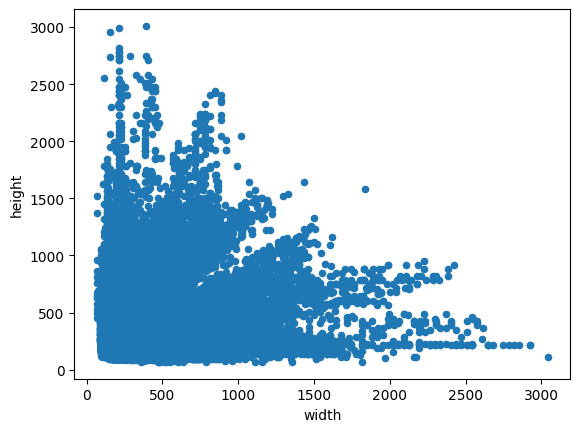

In [10]:
df_image_stats.plot.scatter(x="width", y="height")